# 03 · Extreme Value Theory calibration
Peaks-over-threshold: τ₀ = 90th percentile of held-out D²_M, Weibull fitted to the exceedances, S(q) = exp(−((D²−τ₀)/λ)^κ).

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

In [2]:
from src.evt import WeibullTail
from src.mfa import MFA
for s in ['passage', 'query']:
    e = WeibullTail.load(f'results/models/evt_{s}.json')
    print(s, e, ' threshold D* at alpha=0.01:', round(e.threshold(0.01), 1))

passage WeibullTail(tau0=584.042018179798, kappa=1.0112160453753845, lam=92.48814475572411, tail_percentile=90.0, n_exceed=128, ks_stat=0.07261070794257934, ks_pvalue=0.4871416200569223)  threshold D* at alpha=0.01: 1002.8
query WeibullTail(tau0=501.8868260440485, kappa=1.0574919291775382, lam=52.91170735749897, tail_percentile=90.0, n_exceed=254, ks_stat=0.04234898087026273, ks_pvalue=0.7359552891002347)  threshold D* at alpha=0.01: 726.1


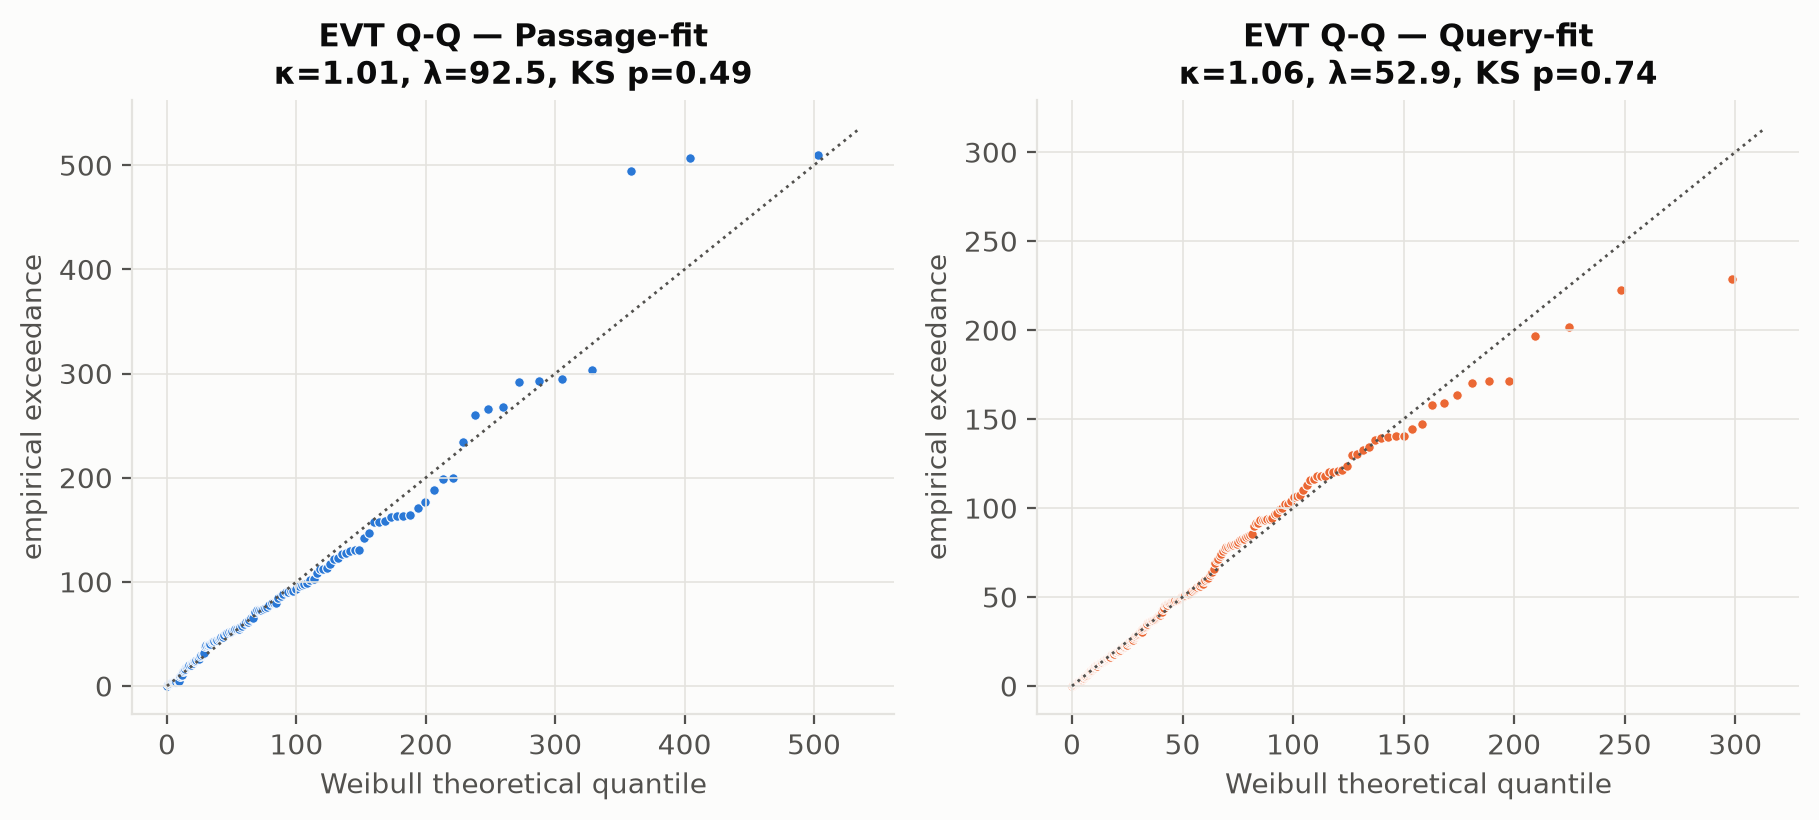

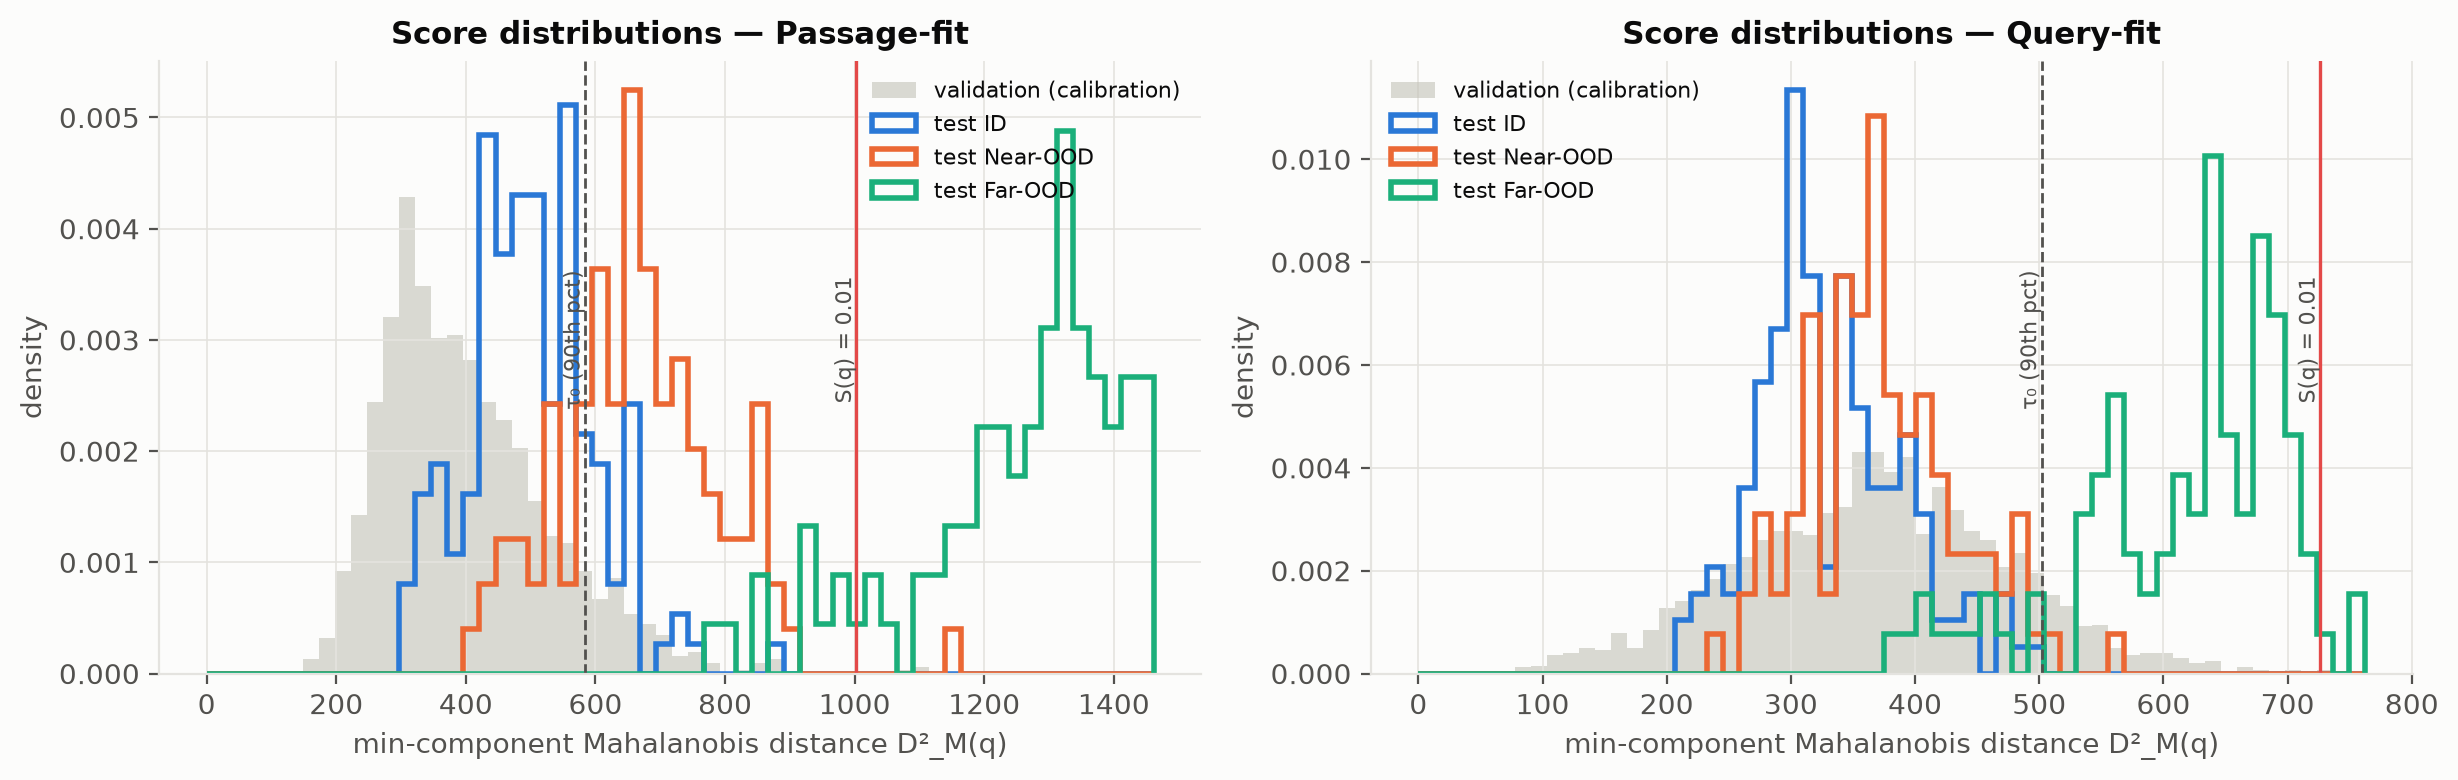

In [3]:
display(Image('results/evt_qq.png'))
display(Image('results/score_dist.png'))

## Sensitivity to α

In [4]:
op = pd.read_csv('results/operating_points.csv')
op[op.method.str.contains('EVT')].round(3)

,source,method,rule,ID pass rate,Near-OOD reject rate,Far-OOD reject rate
7,passage,MFA + EVT (proposed),S(q) < 0.5,0.920,0.57,1.00
8,passage,MFA + EVT (proposed),S(q) < 0.2,0.980,0.27,1.00
9,passage,MFA + EVT (proposed),S(q) < 0.1,0.993,0.16,0.99
10,passage,MFA + EVT (proposed),S(q) < 0.05,0.993,0.06,0.96
11,passage,MFA + EVT (proposed),S(q) < 0.01,1.000,0.01,0.89
12,passage,MFA + EVT (proposed),S(q) < 0.001,1.000,0.00,0.72
13,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.5 (3-fold CV),0.740,0.82,1.00
14,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.2 (3-fold CV),0.907,0.65,1.00
15,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.1 (3-fold CV),0.953,0.47,1.00
16,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.05 (3-fold CV),0.973,0.31,1.00
